In [4]:
import sys, os
sys.path.append(os.path.abspath(".."))   # pour pouvoir importer des fonctions depuis utils qui est à la racine

from torchvision import transforms
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
import torch
from tqdm import tqdm
from utils import ImageDataset, get_device, random_90_rotation

In [5]:
device = get_device()
print(f"Using device: {device}")

# Choisir le GPU et vérifier
torch.cuda.set_device(0)
print(torch.cuda.current_device())  # doit afficher le numéro choisi dans torch.cuda.set_device()
print(torch.cuda.get_device_name(torch.cuda.current_device()))

Using device: cuda
0
Tesla V100S-PCIE-32GB


In [6]:
crop_size = 32
batch_size = 64

In [7]:
# transformations ajoutées pour faire de la data augmentation autrement il y a de l'overfitting

transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.Lambda(random_90_rotation),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

train_dataset = ImageDataset(partial_path="../data/dataset_crops/train_32x32", transform=transform)

In [8]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4)

In [ ]:
print(len(train_dataset))

imgs, attributs, classes = next(iter(train_loader))
print(imgs.shape, attributs.shape, classes.shape)

455135
torch.Size([64, 3, 32, 32]) torch.Size([64, 60]) torch.Size([64])


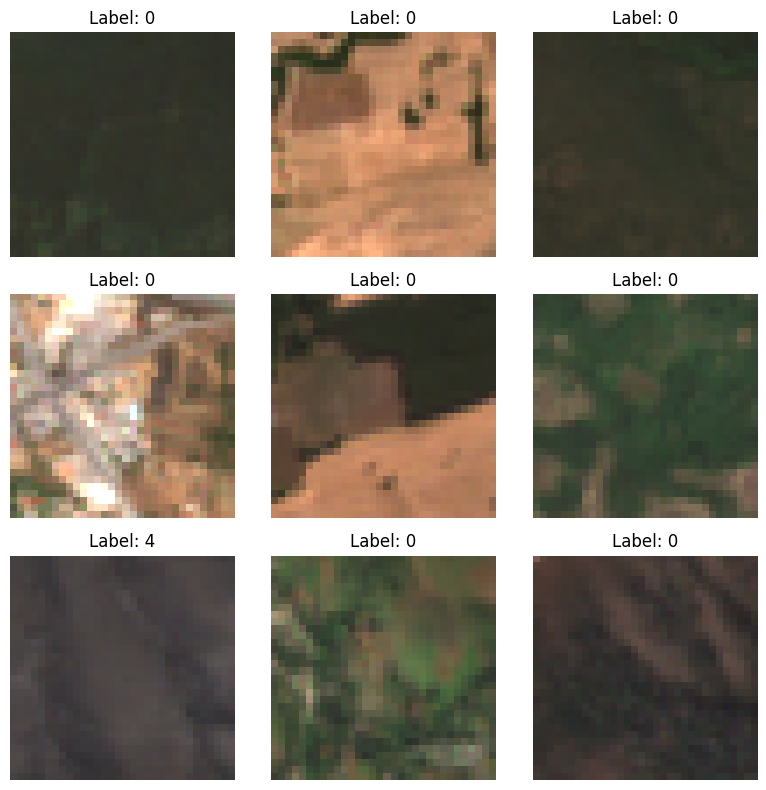

In [10]:
# Afficher une grille 3x3 d'exemples
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
for i in range(3):
    for j in range(3):
        imgs, attributs, classes = next(iter(train_loader))
        axes[i, j].imshow((imgs[0].permute(1, 2, 0).numpy() + 1)/2)
        axes[i, j].set_title(f"Label: {classes[0]}")
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

In [11]:
for imgs, attributs, classes in tqdm(train_loader):
    imgs, attributs, classes = imgs.to(device), attributs.to(device), classes.to(device)


100%|██████████| 7112/7112 [02:01<00:00, 58.57it/s]
